# High-Variance Species vs Defense Score (Recalled Species)

Do plants carrying more **high-variance species** (species whose relative abundance swings a lot from sample to sample) have higher defense scores?

**High-variance species** are defined on the seasonal plant samples, the same sample set used for the rare/core definitions:
- Only species present in ≥ `min_prevalence` (10%) of seasonal samples are ranked. Rare species are left out: a species seen in a handful of samples has a huge CV by construction, and rare species are already covered by the dysbiosis calls.
- **Main definition, CV across samples:** standard deviation / mean of the % abundance (absent = 0). The top `high_variance_quantile` (25%) of species by CV are "high variance".
- **Alternative, within-timepoint SD:** SD of log10(% + 0.05) after centring each timepoint, so species that only vary because of the seasonal trend aren't counted. Used in the sensitivity section.

**Per-sample measures:**
- `high_var_total_abund`: % of the sample's reads in high-variance species.
- `high_var_fraction_present`: of the ranked species present in the sample, the fraction that are high variance (the "preponderance").

**Defense score:** the 148-gene load-correlated set, summed z-scores / number of genes, as in `dysbiosis_calls_and_defense_score_recalled_species.ipynb`.

**Tests:** Spearman correlation, then OLS with timepoint fixed effects (both the microbiome and the defense score change over the season), adding log10 bacterial load (`ham16s`) and rare-species abundance to check the signal isn't just load or dysbiosis.

Species data are cleaned as in the other notebooks in this folder (`AbundR >= 1`; `samples_to_drop` empty for now).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import zscore, spearmanr, ttest_ind

###Define Thresholds
min_prevalence = 0.1  # seasonal prevalence a species needs to be ranked
high_variance_quantile = 0.25  # top fraction of ranked species called high variance
rare_species_definition_threshold = 0.1
log_pseudocount = 0.05  # % of reads, the table's detection floor

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_gene_list["gene"].tolist())
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

total_load = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv", index_col=0
)["ham16s"]
trimmed_metadata["log10_load"] = np.log10(trimmed_metadata["sampID"].map(total_load))

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


## Species abundance

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
sample_timepoint = plant_microbiome.groupby("Sample")["timepoint"].first()

seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_matrix = species_abundance_matrix.loc[seasonal_samples]
seasonal_prevalence = (seasonal_matrix > 0).mean()
rare_species = seasonal_prevalence.index[seasonal_prevalence < rare_species_definition_threshold]
ranked_species = seasonal_prevalence.index[seasonal_prevalence >= min_prevalence]
print(f"Plant samples: {len(species_abundance_matrix)} ({len(seasonal_samples)} seasonal)")
print(f"Species ranked for variability (seasonal prevalence >= {min_prevalence:.0%}): {len(ranked_species)}")

Plant samples: 432 (224 seasonal)
Species ranked for variability (seasonal prevalence >= 10%): 221


## Species variability

Two variability measures for each ranked species, computed on the seasonal samples. The CV is the main one. The within-timepoint SD removes the seasonal trend first.

In [4]:
species_stats = pd.DataFrame(
    {
        "prevalence": seasonal_prevalence[ranked_species],
        "mean_abund": seasonal_matrix[ranked_species].mean(),
        "sd_abund": seasonal_matrix[ranked_species].std(),
    }
)
species_stats["cv"] = species_stats["sd_abund"] / species_stats["mean_abund"]

log_seasonal = np.log10(seasonal_matrix[ranked_species] + log_pseudocount)
within_timepoint = log_seasonal - log_seasonal.groupby(sample_timepoint.loc[seasonal_samples]).transform("mean")
species_stats["within_timepoint_sd_log"] = within_timepoint.std()


def top_fraction(series, fraction):
    return series.index[series >= series.quantile(1 - fraction)]


high_variance_species = top_fraction(species_stats["cv"], high_variance_quantile)
species_stats["high_variance"] = species_stats.index.isin(high_variance_species)
print(f"High-variance species (top {high_variance_quantile:.0%} by CV): {len(high_variance_species)}")
print(
    "Overlap with top species by within-timepoint SD:",
    len(set(high_variance_species) & set(top_fraction(species_stats["within_timepoint_sd_log"], high_variance_quantile))),
)
species_stats.to_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/high_variance_species_recalled_species.csv"
)
species_stats.sort_values("cv", ascending=False).head(25).round(3)

High-variance species (top 25% by CV): 56
Overlap with top species by within-timepoint SD: 7


,prevalence,mean_abund,sd_abund,cv,within_timepoint_sd_log,high_variance
Species,,,,,,
s__Terracoccus luteus,0.107,0.100,1.294,12.992,0.220,True
s__Sphingomonas_L_486704 olei,0.134,0.098,1.002,10.172,0.244,True
s__Flavobacterium sangjuense,0.210,0.122,0.804,6.615,0.301,True
s__Nocardioides_A_392796 cynanchi,0.156,0.055,0.348,6.328,0.230,True
s__Amycolatopsis_D_380400 oliviviridis,0.138,0.045,0.287,6.312,0.243,True
s__DSM-44207 sp900101335,0.219,0.079,0.451,5.744,0.287,True
s__Pseudomonas_E_647464 allii,0.312,0.292,1.536,5.264,0.422,True
s__Sphingomonas_R_483406 montana,0.121,0.032,0.169,5.239,0.225,True
s__Kineosporia aurantiaca,0.112,0.018,0.093,5.182,0.165,True


Spearman CV vs prevalence: -0.77 | CV vs mean abundance: -0.51


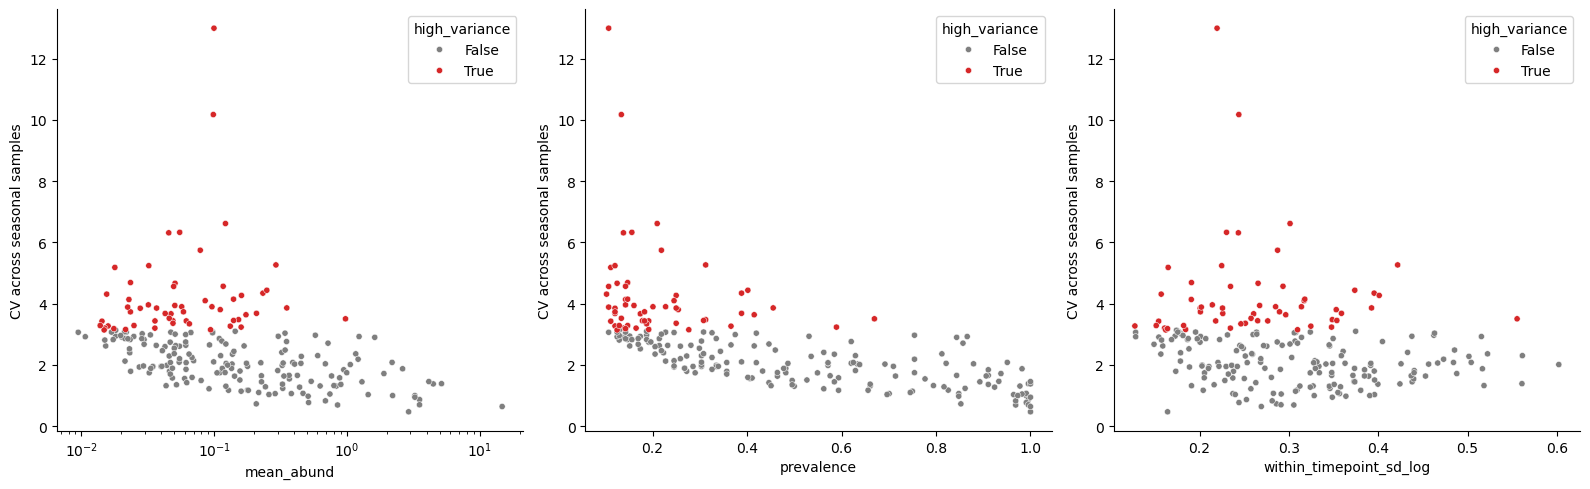

In [5]:
# CV depends strongly on prevalence and mean abundance; check what the high-variance set is made of
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor("white")
for ax, x in zip(axes, ["mean_abund", "prevalence", "within_timepoint_sd_log"]):
    sns.scatterplot(
        data=species_stats,
        x=x,
        y="cv",
        hue="high_variance",
        palette={True: "tab:red", False: "tab:gray"},
        s=20,
        ax=ax,
    )
    if x == "mean_abund":
        ax.set_xscale("log")
    ax.set_ylabel("CV across seasonal samples")
    sns.despine(ax=ax)
plt.tight_layout()
print(
    "Spearman CV vs prevalence:",
    round(spearmanr(species_stats["cv"], species_stats["prevalence"])[0], 2),
    "| CV vs mean abundance:",
    round(spearmanr(species_stats["cv"], species_stats["mean_abund"])[0], 2),
)

## Per-sample high-variance measures

In [6]:
def high_variance_measures(species_set):
    present = species_abundance_matrix[ranked_species] > 0
    return pd.DataFrame(
        {
            "high_var_total_abund": species_abundance_matrix[species_set].sum(axis=1),
            "high_var_fraction_present": present[species_set].sum(axis=1) / present.sum(axis=1),
        }
    )


sample_measures = high_variance_measures(high_variance_species)
sample_measures["rare_species_total_abund"] = species_abundance_matrix[rare_species].sum(axis=1)

analysis_df = trimmed_metadata[["sampID", "timepoint", "Experiment Type", "Defense Score", "log10_load"]].join(
    sample_measures, on="sampID", how="inner"
)
print("Transcriptomes with a microbiome profile:", len(analysis_df))
print("  with bacterial load too:", analysis_df["log10_load"].notna().sum())
analysis_df[sample_measures.columns].describe().round(3)

Transcriptomes with a microbiome profile: 426
  with bacterial load too: 423


,high_var_total_abund,high_var_fraction_present,rare_species_total_abund
count,426.000,426.000,426.000
mean,4.267,0.105,1.428
std,5.220,0.039,1.967
min,0.051,0.014,0.000
25%,1.468,0.077,0.377
50%,2.461,0.102,0.772
75%,4.749,0.130,1.675
max,46.475,0.212,21.240


## Correlation with defense score

Spearman correlations across all samples, then OLS with timepoint fixed effects. Each measure is z-scored so the coefficients are comparable (change in defense score per SD of the measure).

high_var_total_abund: Spearman rho = 0.158, p = 0.001 (n = 426)
high_var_fraction_present: Spearman rho = 0.190, p = 7.8e-05 (n = 426)


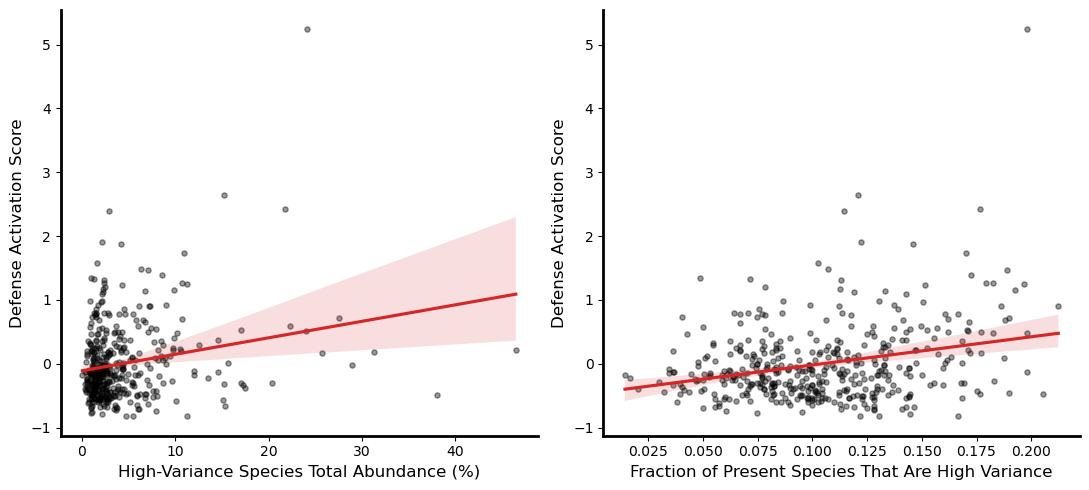

In [7]:
measures = ["high_var_total_abund", "high_var_fraction_present"]
for measure in measures:
    rho, p = spearmanr(analysis_df[measure], analysis_df["Defense Score"])
    print(f"{measure}: Spearman rho = {rho:.3f}, p = {p:.2g} (n = {len(analysis_df)})")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.patch.set_facecolor("white")
for ax, measure in zip(axes, measures):
    sns.regplot(
        data=analysis_df,
        x=measure,
        y="Defense Score",
        scatter_kws={"alpha": 0.4, "s": 14, "color": "black"},
        line_kws={"color": "tab:red"},
        ax=ax,
    )
    ax.set_ylabel("Defense Activation Score", fontsize=12)
    sns.despine(ax=ax)
    ax.spines["bottom"].set_linewidth(2)
    ax.spines["left"].set_linewidth(2)
axes[0].set_xlabel("High-Variance Species Total Abundance (%)", fontsize=12)
axes[1].set_xlabel("Fraction of Present Species That Are High Variance", fontsize=12)
plt.tight_layout()

In [8]:
def fit_models(df, measure):
    """Defense score ~ timepoint + z(measure), then adding load and rare-species abundance."""
    df = df.assign(
        x=zscore(df[measure]),
        rare_z=zscore(df["rare_species_total_abund"]),
    )
    with_load = df.dropna(subset=["log10_load"])
    formulas = {
        "timepoint": ("Q('Defense Score') ~ C(timepoint) + x", df),
        "timepoint + load": ("Q('Defense Score') ~ C(timepoint) + log10_load + x", with_load),
        "timepoint + load + rare": ("Q('Defense Score') ~ C(timepoint) + log10_load + rare_z + x", with_load),
    }
    rows = []
    for model, (formula, data) in formulas.items():
        fit = smf.ols(formula, data=data).fit()
        rows.append(
            {
                "measure": measure,
                "model": model,
                "n": int(fit.nobs),
                "coef (per SD)": fit.params["x"],
                "t": fit.tvalues["x"],
                "p": fit.pvalues["x"],
            }
        )
    return rows


model_results = pd.DataFrame([row for measure in measures for row in fit_models(analysis_df, measure)])
model_results.round(4)

,measure,model,n,coef (per SD),t,p
0,high_var_total_abund,timepoint,426,0.0021,0.0876,0.9302
1,high_var_total_abund,timepoint + load,423,-0.0110,-0.4898,0.6246
2,high_var_total_abund,timepoint + load + rare,423,-0.0074,-0.3268,0.7440
3,high_var_fraction_present,timepoint,426,-0.0404,-1.4220,0.1559
4,high_var_fraction_present,timepoint + load,423,-0.0262,-0.9665,0.3344
5,high_var_fraction_present,timepoint + load + rare,423,-0.0217,-0.7962,0.4264


Top quartile vs rest: t = 3.500, p = 0.00052


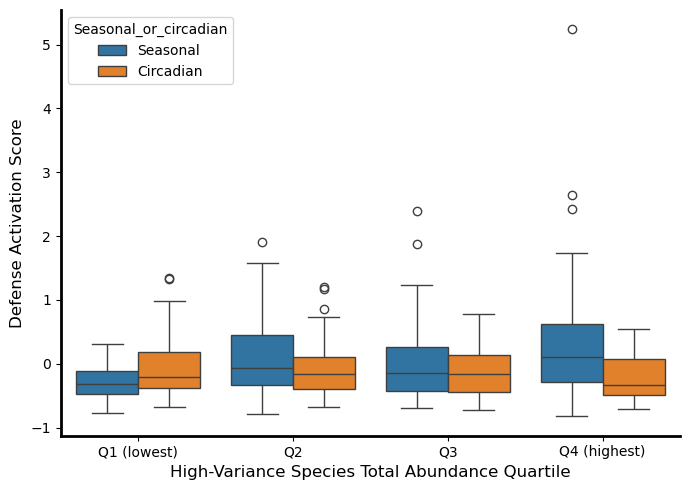

In [9]:
# Defense score by quartile of high-variance abundance, seasonal and circadian samples
analysis_df["High-variance abundance quartile"] = pd.qcut(
    analysis_df["high_var_total_abund"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]
)
analysis_df["Seasonal_or_circadian"] = np.where(
    analysis_df["Experiment Type"] == "Long Term", "Seasonal", "Circadian"
)
fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor("white")
sns.boxplot(
    data=analysis_df,
    x="High-variance abundance quartile",
    y="Defense Score",
    hue="Seasonal_or_circadian",
    ax=ax,
)
plt.xlabel("High-Variance Species Total Abundance Quartile", fontsize=12)
plt.ylabel("Defense Activation Score", fontsize=12)
sns.despine()
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_linewidth(2)
plt.tight_layout()

top = analysis_df.loc[analysis_df["High-variance abundance quartile"] == "Q4 (highest)", "Defense Score"]
rest = analysis_df.loc[analysis_df["High-variance abundance quartile"] != "Q4 (highest)", "Defense Score"]
t_stat, p_value = ttest_ind(top, rest)
print(f"Top quartile vs rest: t = {t_stat:.3f}, p = {p_value:.2g}")

## Is it a few species?

High-variance abundance could be driven by one or two abundant species (e.g. a *Pseudomonas* bloom). Per-species correlations with the defense score (with timepoint), and the main model re-fitted leaving out each of the 5 biggest contributors.

In [10]:
species_rows = []
for species in high_variance_species:
    df = analysis_df.assign(x=zscore(np.log10(analysis_df["sampID"].map(species_abundance_matrix[species]) + log_pseudocount)))
    fit = smf.ols("Q('Defense Score') ~ C(timepoint) + x", data=df).fit()
    species_rows.append(
        {
            "species": species,
            "mean_abund": species_stats.loc[species, "mean_abund"],
            "cv": species_stats.loc[species, "cv"],
            "coef (per SD log abundance)": fit.params["x"],
            "p": fit.pvalues["x"],
        }
    )
high_variance_species_effects = pd.DataFrame(species_rows).sort_values("p")
print(
    "High-variance species with a positive / negative link to defense (p < 0.05):",
    ((high_variance_species_effects["p"] < 0.05) & (high_variance_species_effects["coef (per SD log abundance)"] > 0)).sum(),
    "/",
    ((high_variance_species_effects["p"] < 0.05) & (high_variance_species_effects["coef (per SD log abundance)"] < 0)).sum(),
    f"of {len(high_variance_species_effects)}",
)
high_variance_species_effects.head(20).round(4)

High-variance species with a positive / negative link to defense (p < 0.05): 4 / 4 of 56


,species,mean_abund,cv,coef (per SD log abundance),p
3,g__Ideonella_A_591966 Genus,0.0234,4.6877,-0.0828,0.0002
21,s__Methylophilus methylotrophus,0.0570,3.8992,-0.0743,0.0005
30,s__Nocardioides_A_392796 psychrotolerans,0.0458,3.5218,-0.0769,0.0010
46,s__Sphingomonas_L_486704 olei,0.0985,10.1722,0.0744,0.0021
48,s__Sphingomonas_R_483406 montana,0.0322,5.2389,0.0601,0.0055
34,s__Polaromonas sp002001015,0.0249,3.2852,-0.0601,0.0086
11,s__Aureimonas_A_501548 sp001423245,0.0489,3.4411,0.0516,0.0247
25,s__Microbacterium_A_383321 testaceum_F,0.1527,3.4773,0.0571,0.0280
32,s__Noviherbaspirillum_A_569121 massiliense,0.0223,3.8866,-0.0417,0.0515
51,s__Telluria mixta,0.2491,4.4372,-0.0504,0.0652


In [11]:
top_contributors = species_stats.loc[high_variance_species, "mean_abund"].sort_values(ascending=False).head(5).index
leave_one_out = []
for species in top_contributors:
    reduced = high_variance_species.drop(species)
    df = analysis_df.drop(columns=measures).join(high_variance_measures(reduced), on="sampID")
    for row in fit_models(df, "high_var_total_abund")[:1]:
        leave_one_out.append({"left out": species, **row})
pd.DataFrame(leave_one_out).drop(columns=["measure", "model"]).round(4)

,left out,n,coef (per SD),t,p
0,s__Duganella zoogloeoides,426,0.0058,0.2446,0.8069
1,s__Aquaspirillum arcticum,426,0.0083,0.3348,0.7380
2,s__Pseudomonas_E_647464 allii,426,0.0012,0.0481,0.9616
3,s__Telluria mixta,426,0.0064,0.2734,0.7847
4,s__Brevundimonas huaxiensis,426,-0.0010,-0.0417,0.9668


## Sensitivity to the definition

Main model (timepoint + load) for both variability measures and three cutoffs (top 10%, 25%, 50% of ranked species).

In [12]:
sensitivity_rows = []
for definition in ["cv", "within_timepoint_sd_log"]:
    for fraction in [0.1, 0.25, 0.5]:
        species_set = top_fraction(species_stats[definition], fraction)
        df = analysis_df.drop(columns=measures).join(high_variance_measures(species_set), on="sampID")
        for measure in measures:
            row = fit_models(df, measure)[1]
            sensitivity_rows.append({"definition": definition, "top fraction": fraction, "n species": len(species_set), **row})
sensitivity_results = pd.DataFrame(sensitivity_rows).drop(columns=["model"])
sensitivity_results.round(4)

,definition,top fraction,n species,measure,n,coef (per SD),t,p
0,cv,0.10,23,high_var_total_abund,423,0.0239,1.1015,0.2714
1,cv,0.10,23,high_var_fraction_present,423,-0.0211,-0.9411,0.3473
2,cv,0.25,56,high_var_total_abund,423,-0.0110,-0.4898,0.6246
3,cv,0.25,56,high_var_fraction_present,423,-0.0262,-0.9665,0.3344
4,cv,0.50,111,high_var_total_abund,423,-0.0242,-0.9231,0.3566
5,cv,0.50,111,high_var_fraction_present,423,-0.0582,-1.9246,0.0551
6,within_timepoint_sd_log,0.10,23,high_var_total_abund,423,-0.0148,-0.6555,0.5125
7,within_timepoint_sd_log,0.10,23,high_var_fraction_present,423,-0.0272,-1.1610,0.2464
8,within_timepoint_sd_log,0.25,56,high_var_total_abund,423,-0.0109,-0.4704,0.6384
9,within_timepoint_sd_log,0.25,56,high_var_fraction_present,423,-0.0235,-0.8972,0.3702


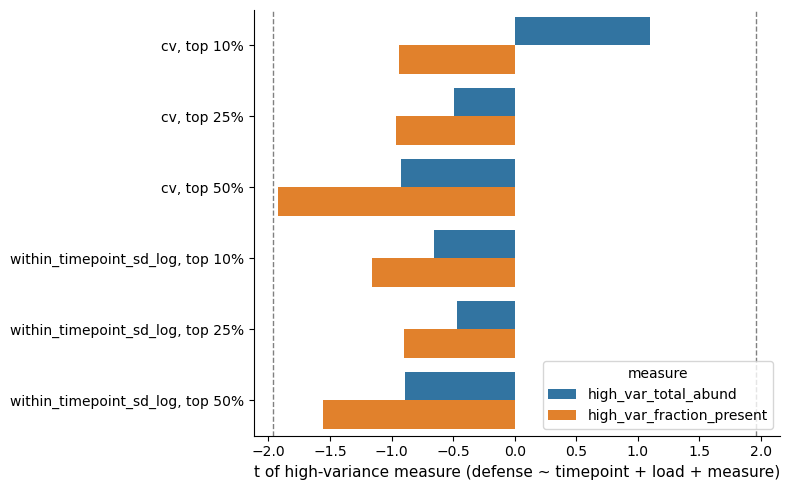

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor("white")
sensitivity_results["setting"] = (
    sensitivity_results["definition"] + ", top " + (sensitivity_results["top fraction"] * 100).astype(int).astype(str) + "%"
)
sns.barplot(data=sensitivity_results, x="t", y="setting", hue="measure", ax=ax)
ax.axvline(1.96, color="gray", linestyle="dashed", linewidth=1)
ax.axvline(-1.96, color="gray", linestyle="dashed", linewidth=1)
ax.set_xlabel("t of high-variance measure (defense ~ timepoint + load + measure)", fontsize=11)
ax.set_ylabel("")
sns.despine()
plt.tight_layout()

## Shared seasonal trend

Timepoint means of the defense score and of high-variance species abundance, seasonal samples only. If both drift together over the season, the raw correlation above can come from timing alone, which is what the timepoint fixed effects remove.

Timepoint-mean Spearman, defense vs high-variance abundance: 0.515 | vs fraction present: 0.694


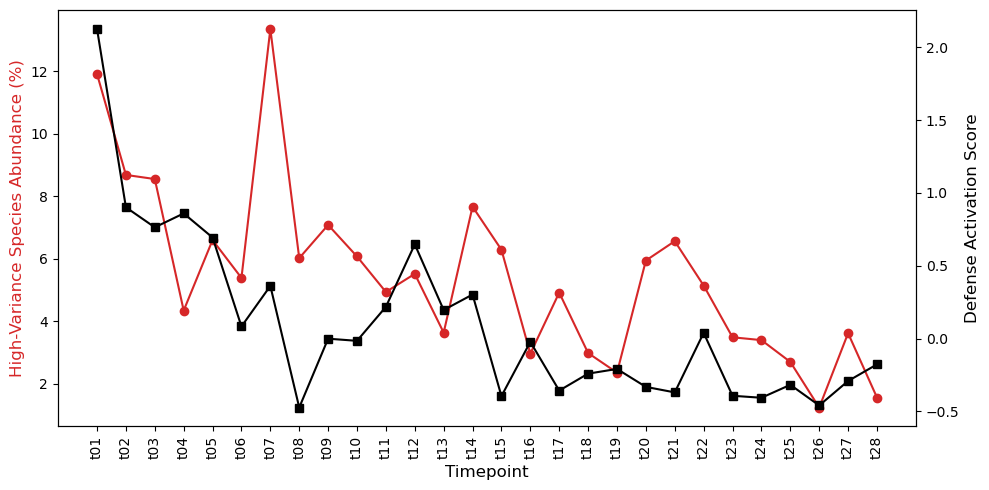

In [14]:
seasonal_df = analysis_df.loc[analysis_df["Seasonal_or_circadian"] == "Seasonal"]
timepoint_means = seasonal_df.groupby("timepoint")[["Defense Score", "high_var_total_abund", "high_var_fraction_present"]].mean()
print(
    "Timepoint-mean Spearman, defense vs high-variance abundance:",
    round(spearmanr(timepoint_means["Defense Score"], timepoint_means["high_var_total_abund"])[0], 3),
    "| vs fraction present:",
    round(spearmanr(timepoint_means["Defense Score"], timepoint_means["high_var_fraction_present"])[0], 3),
)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor("white")
ax.plot(timepoint_means.index, timepoint_means["high_var_total_abund"], color="tab:red", marker="o", label="High-variance species abundance (%)")
ax.set_ylabel("High-Variance Species Abundance (%)", color="tab:red", fontsize=12)
ax.tick_params(axis="x", rotation=90)
ax_defense = ax.twinx()
ax_defense.plot(timepoint_means.index, timepoint_means["Defense Score"], color="black", marker="s", label="Defense score")
ax_defense.set_ylabel("Defense Activation Score", fontsize=12)
ax.set_xlabel("Timepoint", fontsize=12)
plt.tight_layout()

## Individual species

Each of the 221 ranked species (seasonal prevalence ≥ 10%) is tested on its own:

`defense score ~ timepoint + log10 load + z(log10(% + 0.05))`

Timepoint and load are in the model so that a species isn't credited for the seasonal trend or for total bacterial quantity. The coefficient is the change in defense score per SD of the species' log abundance. P-values are BH-corrected across all 221 species. Testing every ranked species, not only the high-variance set, means variability can be compared with impact over its whole range.

In [15]:
from statsmodels.stats.multitest import multipletests

model_df = analysis_df.dropna(subset=["log10_load"])
log_abundance = np.log10(
    species_abundance_matrix.loc[model_df["sampID"], ranked_species] + log_pseudocount
).set_index(model_df.index)

species_effect_rows = []
for species in ranked_species:
    fit = smf.ols(
        "Q('Defense Score') ~ C(timepoint) + log10_load + x",
        data=model_df.assign(x=zscore(log_abundance[species])),
    ).fit()
    species_effect_rows.append(
        {
            "species": species,
            "coef (per SD)": fit.params["x"],
            "t": fit.tvalues["x"],
            "p": fit.pvalues["x"],
        }
    )
species_effects = pd.DataFrame(species_effect_rows).set_index("species").join(species_stats)
species_effects["q"] = multipletests(species_effects["p"], method="fdr_bh")[1]
species_effects["abs coef"] = species_effects["coef (per SD)"].abs()
species_effects["cv rank (%)"] = species_effects["cv"].rank(pct=True) * 100
species_effects.to_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/high_variance_species_defense_effects_recalled_species.csv"
)

print(f"Species tested: {len(species_effects)} (n = {len(model_df)} samples)")
for label, subset in [("all ranked", species_effects), ("high variance", species_effects.loc[species_effects["high_variance"]])]:
    print(
        f"{label}: p < 0.05 {(subset['p'] < 0.05).sum()} / {len(subset)} "
        f"(~{0.05 * len(subset):.0f} expected), q < 0.1 {(subset['q'] < 0.1).sum()}, q < 0.05 {(subset['q'] < 0.05).sum()}"
    )

Species tested: 221 (n = 423 samples)
all ranked: p < 0.05 32 / 221 (~11 expected), q < 0.1 17, q < 0.05 13
high variance: p < 0.05 7 / 56 (~3 expected), q < 0.1 5, q < 0.05 3


### High-variance species linked to the defense score

High-variance species (top 25% by CV) with nominal p < 0.05, sorted by p. `q` is corrected across all 221 species.

In [16]:
effect_columns = ["coef (per SD)", "t", "p", "q", "cv", "cv rank (%)", "within_timepoint_sd_log", "prevalence", "mean_abund"]
high_variance_hits = species_effects.loc[species_effects["high_variance"] & (species_effects["p"] < 0.05), effect_columns].sort_values("p")
high_variance_hits.round(4)

,coef (per SD),t,p,q,cv,cv rank (%),within_timepoint_sd_log,prevalence,mean_abund
species,,,,,,,,,
s__Sphingomonas_R_483406 montana,0.0658,3.2379,0.0013,0.0323,5.2389,96.8326,0.2247,0.1205,0.0322
s__Sphingomonas_L_486704 olei,0.0690,3.0274,0.0026,0.0494,10.1722,99.5475,0.2439,0.1339,0.0985
s__Methylophilus methylotrophus,-0.0607,-2.9978,0.0029,0.0494,3.8992,90.0452,0.2851,0.2277,0.0570
g__Ideonella_A_591966 Genus,-0.0608,-2.8123,0.0052,0.0742,4.6877,95.9276,0.1909,0.1473,0.0234
s__VAYN01 sp005885405,0.0611,2.8007,0.0054,0.0742,3.8553,88.2353,0.2256,0.2500,0.0368
s__Polaromonas sp002001015,-0.0564,-2.6082,0.0095,0.1047,3.2852,79.6380,0.1821,0.1473,0.0249
s__Nocardioides_A_392796 psychrotolerans,-0.0463,-2.0307,0.0430,0.3066,3.5218,84.1629,0.2576,0.1339,0.0458


In [17]:
print("All ranked species with q < 0.1 (high-variance or not):")
species_effects.loc[species_effects["q"] < 0.1, effect_columns + ["high_variance"]].sort_values("p").round(4)

All ranked species with q < 0.1 (high-variance or not):


,coef (per SD),t,p,q,cv,cv rank (%),within_timepoint_sd_log,prevalence,mean_abund,high_variance
species,,,,,,,,,,
s__Pseudomonas_E_647464 viridiflava,0.1382,6.1560,0.0000,0.0000,2.0816,43.4389,0.5040,0.9509,2.1880,False
s__Caldora sp010672925,-0.2029,-5.1243,0.0000,0.0001,2.8996,64.2534,0.3141,0.8438,1.6199,False
s__Aldersonia kunmingensis,0.0872,4.3818,0.0000,0.0011,1.9484,34.3891,0.2296,0.3036,0.0346,False
s__Chryseobacterium_A_796612 polytrichastri,0.0926,4.1432,0.0000,0.0024,2.9258,65.6109,0.5155,0.8661,1.2341,False
s__Kordiimonas sp002401685,-0.1806,-4.0377,0.0001,0.0029,0.4686,0.4525,0.1641,1.0000,2.9153,False
s__Nocardioides_A_392796 sp001428125,0.0815,3.8062,0.0002,0.0057,1.3092,13.1222,0.3123,0.9777,0.8311,False
s__Nakamurella deserti,0.0806,3.7834,0.0002,0.0057,1.6587,24.8869,0.3479,0.9107,0.3667,False
s__Nocardioides_A_392796 sp000620645,0.0854,3.3568,0.0009,0.0241,1.0338,6.3348,0.2399,0.6964,0.2585,False
s__Sphingomonas_R_483406 montana,0.0658,3.2379,0.0013,0.0323,5.2389,96.8326,0.2247,0.1205,0.0322,True


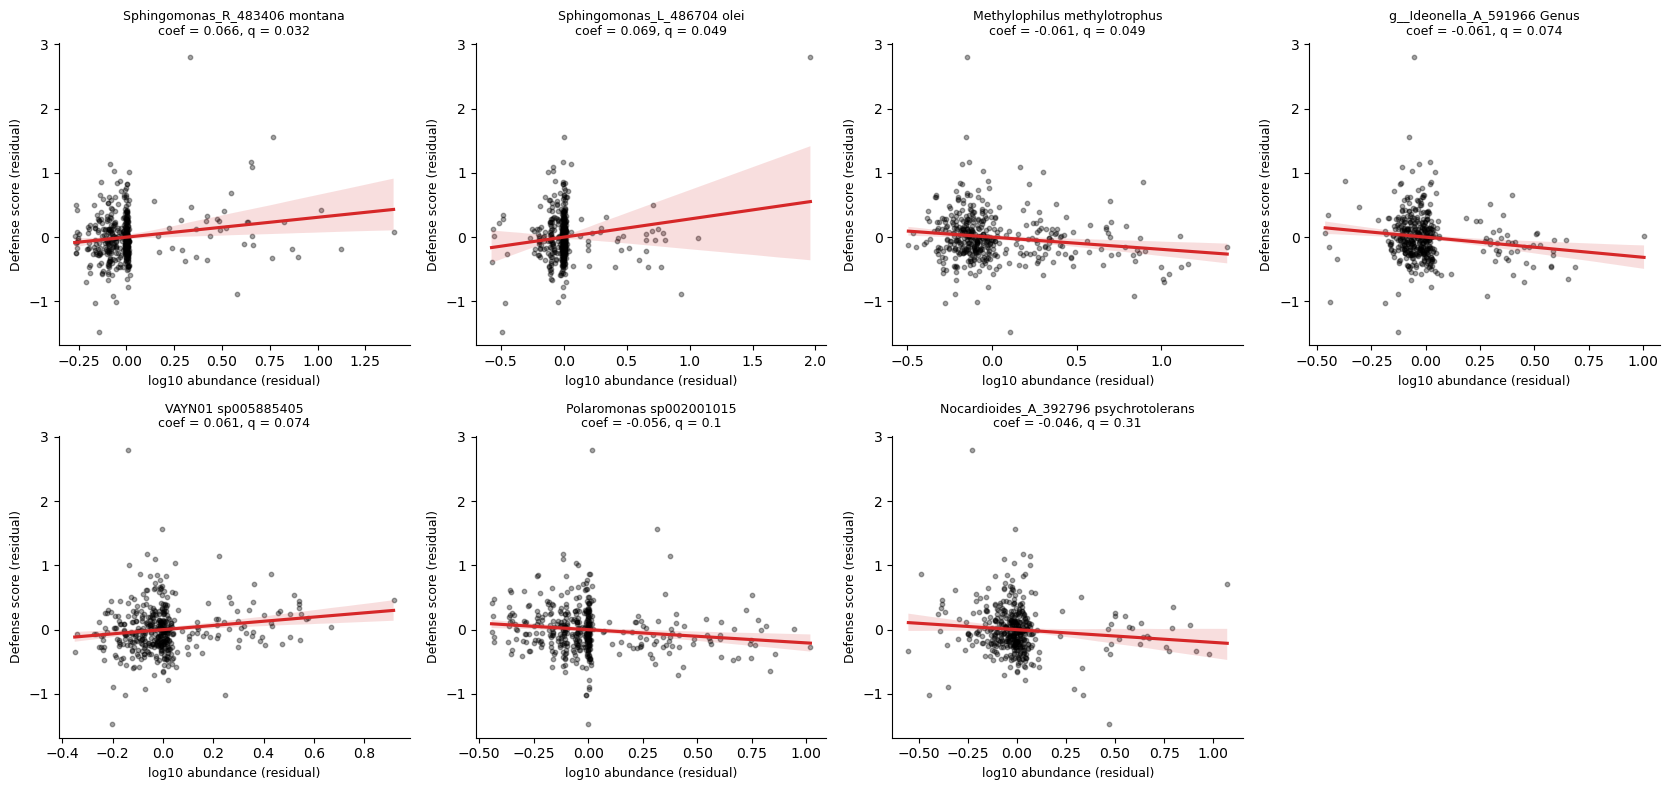

In [18]:
# Partial-residual plots for the high-variance hits: defense score and species abundance
# with timepoint and load regressed out of both
plot_species = high_variance_hits.index[:8]
if len(plot_species) == 0:
    print("No high-variance species with p < 0.05")
else:
    covariate_formula = "C(timepoint) + log10_load"
    defense_resid = smf.ols(f"Q('Defense Score') ~ {covariate_formula}", data=model_df).fit().resid
    n_cols = 4
    n_rows = int(np.ceil(len(plot_species) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4 * n_rows), squeeze=False)
    fig.patch.set_facecolor("white")
    for ax, species in zip(axes.flatten(), plot_species):
        abundance_resid = smf.ols(
            f"x ~ {covariate_formula}", data=model_df.assign(x=log_abundance[species])
        ).fit().resid
        sns.regplot(
            x=abundance_resid,
            y=defense_resid,
            ax=ax,
            scatter_kws={"alpha": 0.35, "s": 10, "color": "black"},
            line_kws={"color": "tab:red"},
        )
        row = species_effects.loc[species]
        ax.set_title(f"{species.removeprefix('s__')}\ncoef = {row['coef (per SD)']:.3f}, q = {row['q']:.2g}", fontsize=9)
        ax.set_xlabel("log10 abundance (residual)", fontsize=9)
        ax.set_ylabel("Defense score (residual)", fontsize=9)
        sns.despine(ax=ax)
    for ax in axes.flatten()[len(plot_species):]:
        ax.set_visible(False)
    plt.tight_layout()

## Does more variability mean more impact?

Across all 221 ranked species, is a species' variability (CV, or within-timepoint SD of log abundance) correlated with the size of its effect on the defense score?

- **|coef|** (effect size per SD of log abundance) is the main measure of impact. **|t|** also depends on how much information there is for a species, so it is shown for comparison.
- CV is strongly tied to prevalence (rarer species have higher CV), so the last model checks whether CV still matters with prevalence and mean abundance held fixed.

In [19]:
variability_rows = []
for variability in ["cv", "within_timepoint_sd_log"]:
    for impact in ["abs coef", "t", "coef (per SD)"]:
        rho, p = spearmanr(species_effects[variability], species_effects[impact].abs() if impact == "t" else species_effects[impact])
        variability_rows.append(
            {"variability": variability, "impact": "|t|" if impact == "t" else impact, "Spearman rho": rho, "p": p}
        )
pd.DataFrame(variability_rows).round(4)

,variability,impact,Spearman rho,p
0,cv,abs coef,-0.1572,0.0194
1,cv,|t|,-0.1513,0.0245
2,cv,coef (per SD),-0.2715,0.0000
3,within_timepoint_sd_log,abs coef,0.0779,0.2490
4,within_timepoint_sd_log,|t|,0.0867,0.1990
5,within_timepoint_sd_log,coef (per SD),-0.0061,0.9276


In [20]:
# Effect size (|coef|) and direction (signed coef) vs CV, holding prevalence and mean abundance fixed
impact_rows = []
for outcome, formula_outcome in [("|coef|", "np.log10(Q('abs coef'))"), ("signed coef", "Q('coef (per SD)')")]:
    fit = smf.ols(
        f"{formula_outcome} ~ np.log10(cv) + np.log10(prevalence) + np.log10(mean_abund)",
        data=species_effects,
    ).fit()
    for term in ["np.log10(cv)", "np.log10(prevalence)", "np.log10(mean_abund)"]:
        impact_rows.append({"outcome": outcome, "term": term, "coef": fit.params[term], "t": fit.tvalues[term], "p": fit.pvalues[term]})
pd.DataFrame(impact_rows).round(4)

,outcome,term,coef,t,p
0,|coef|,np.log10(cv),-0.0583,-0.2143,0.8305
1,|coef|,np.log10(prevalence),-0.0005,-0.0015,0.9988
2,|coef|,np.log10(mean_abund),0.1741,1.4273,0.1549
3,signed coef,np.log10(cv),-0.0139,-0.6689,0.5043
4,signed coef,np.log10(prevalence),0.0292,1.1584,0.2480
5,signed coef,np.log10(mean_abund),-0.0121,-1.2935,0.1972


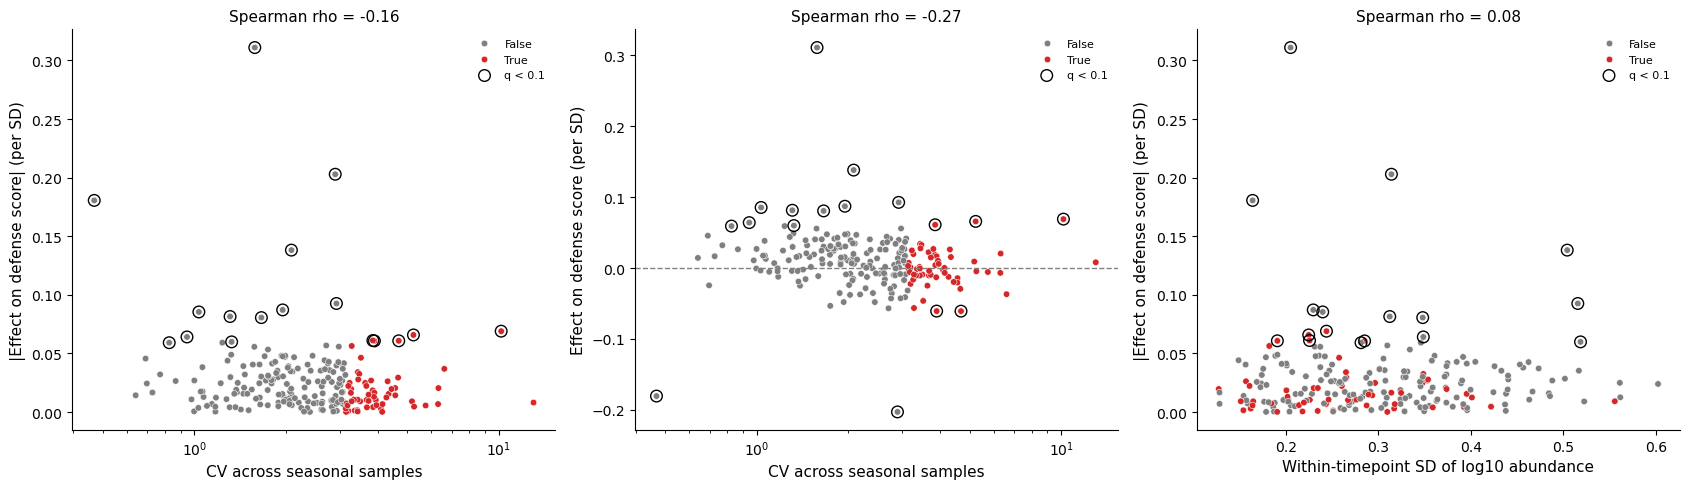

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.patch.set_facecolor("white")
for ax, (x, y, ylabel) in zip(
    axes,
    [
        ("cv", "abs coef", "|Effect on defense score| (per SD)"),
        ("cv", "coef (per SD)", "Effect on defense score (per SD)"),
        ("within_timepoint_sd_log", "abs coef", "|Effect on defense score| (per SD)"),
    ],
):
    sns.scatterplot(
        data=species_effects,
        x=x,
        y=y,
        hue="high_variance",
        palette={True: "tab:red", False: "tab:gray"},
        s=22,
        ax=ax,
    )
    significant = species_effects.loc[species_effects["q"] < 0.1]
    ax.scatter(significant[x], significant[y], s=70, facecolors="none", edgecolors="black", linewidths=1, label="q < 0.1")
    if x == "cv":
        ax.set_xscale("log")
    if y == "coef (per SD)":
        ax.axhline(0, color="gray", linestyle="dashed", linewidth=1)
    rho = spearmanr(species_effects[x], species_effects[y])[0]
    ax.set_title(f"Spearman rho = {rho:.2f}", fontsize=11)
    ax.set_xlabel("CV across seasonal samples" if x == "cv" else "Within-timepoint SD of log10 abundance", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.legend(fontsize=8, frameon=False)
    sns.despine(ax=ax)
plt.tight_layout()

In [22]:
# Effect size by CV quartile, and how many species in each quartile have q < 0.1
species_effects["cv quartile"] = pd.qcut(species_effects["cv"], 4, labels=["Q1 (least variable)", "Q2", "Q3", "Q4 (most variable)"])
species_effects.groupby("cv quartile", observed=True).agg(
    n=("abs coef", "size"),
    median_abs_coef=("abs coef", "median"),
    n_p_below_005=("p", lambda p: (p < 0.05).sum()),
    n_q_below_01=("q", lambda q: (q < 0.1).sum()),
    median_prevalence=("prevalence", "median"),
).round(4)

,n,median_abs_coef,n_p_below_005,n_q_below_01,median_prevalence
cv quartile,,,,,
Q1 (least variable),56,0.0226,13,8,0.8348
Q2,55,0.0244,8,2,0.4643
Q3,55,0.0220,4,2,0.2143
Q4 (most variable),55,0.0143,7,5,0.1741


## Summary (rare species < 10%, top 25% by CV, `AbundR >= 1`)

- Across all samples, plants with more high-variance species do have somewhat higher defense scores (Spearman rho ≈ 0.16 for abundance, 0.19 for fraction present; top quartile vs rest p ≈ 5e-4).
- The seasonal trends line up (timepoint means: rho ≈ 0.5 for abundance, 0.7 for fraction present), and the link disappears once timepoint is in the model (|t| < 1.5 with or without load and rare-species abundance), so it reflects both measures changing over the season rather than plant-to-plant differences at the same time.
- The null result holds across both variability definitions and the 10/25/50% cutoffs, and isn't hidden by any single abundant species (leave-one-out).
- Individually, 8 of the 56 high-variance species are associated with defense within timepoint at p < 0.05 (about 3 expected by chance), but 4 go up and 4 go down, so they cancel out in the summed measures. Which species matter, rather than how variable they are, looks like the more useful question.

**Individual species** (`defense ~ timepoint + log10 load + log abundance`, BH across 221 ranked species):
- 32 of 221 species have p < 0.05 (~11 expected) and 17 have q < 0.1, so individual species do carry signal beyond season and load.
- 5 high-variance species reach q < 0.1: *Sphingomonas_R montana* and *Sphingomonas_L olei* (higher defense), *Methylophilus methylotrophus* and an unresolved *Ideonella_A* (lower defense), and VAYN01 sp005885405 (higher). All are low-prevalence (12–25%) and low-abundance (< 0.1%).
- The strongest effects are not high-variance species: *Pseudomonas viridiflava* (+), *Caldora* sp. (−), *Kordiimonas* sp. (−, a core species with one of the lowest CVs), *Aldersonia*, *Chryseobacterium*, *Nakamurella* and *Nocardioides* (+).

**Variability vs impact:** no. Across the 221 species, CV is weakly *negatively* related to effect size (|coef| rho = −0.16) and to direction (rho = −0.27), but neither survives holding prevalence and mean abundance fixed (p > 0.5). The within-timepoint SD isn't related to effect size at all (rho = 0.08, p = 0.25). The least variable quartile has as many hits as the most variable (8 vs 5 at q < 0.1).